# Practica 01: Exploracion de datos

## Primer contacto con MNIST

In [ ]:
#importamos las librerias 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#importar el dataset
data = pd.read_csv("/content/sample_data/mnist_train_small.csv")

In [ ]:
data

,6,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.581,0.582,0.583,0.584,0.585,0.586,0.587,0.588,0.589,0.590
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19995,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19996,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19997,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


En el dataset, cada imagen es representada por una fila de tamaño 784 (el primer elemento es la etiqueta). El conjunto de datos es una matriz de 19999x785 (o sea que tenemos 19999 numeros etiquetados)

#### En la muestra que hicimos de la matriz, podemos ver que en la primera columna tenemos las etiquetas de cada numero

## Observar muestras en forma matricial y tambien viendo la imagen

In [ ]:
# guardamos en variables las etiquetas y la matriz con formato de 28x28
etiqueta1, imagen1 = data.iloc[0][0], np.array(data.iloc[0][1:]).reshape(28, 28)
etiqueta2, imagen2 = data.iloc[100][0], np.array(data.iloc[100][1:]).reshape(28, 28)

/tmp/ipykernel_4374/3722851055.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  etiqueta1, imagen1 = data.iloc[0][0], np.array(data.iloc[0][1:]).reshape(28, 28)
/tmp/ipykernel_4374/3722851055.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  etiqueta2, imagen2 = data.iloc[100][0], np.array(data.iloc[100][1:]).reshape(28, 28)


In [ ]:
#podemos ver los pixeles de la imagen llamando a imprimir imagen1
imagen1

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  28,  59,
         50,   0,  23,   0,   0,  32, 134, 180, 254, 206,   8,   0,   0,
          0,   0],
       [  

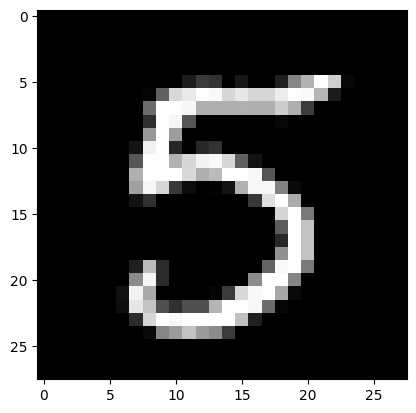

In [ ]:
#mostramos la imagen 1 y despues la dos
plt.imshow(imagen1, cmap = 'gray')

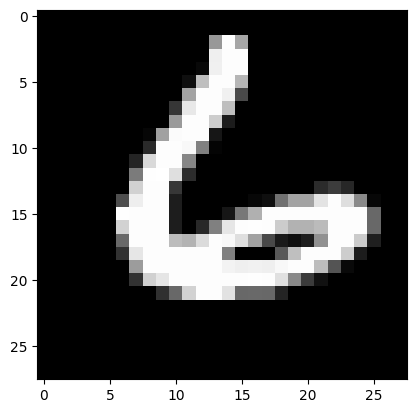

In [ ]:
plt.imshow(imagen2, cmap = 'gray')

##  Exploración de patrones

### Primero exploraremos un poco con distintias imagenes con la misma etiqueta para ver las diferencias

In [ ]:
#separamos la data en etiquetas y pixeles
etiquetas = data.iloc[:, 0]
pixeles = data.iloc[:, 1:]

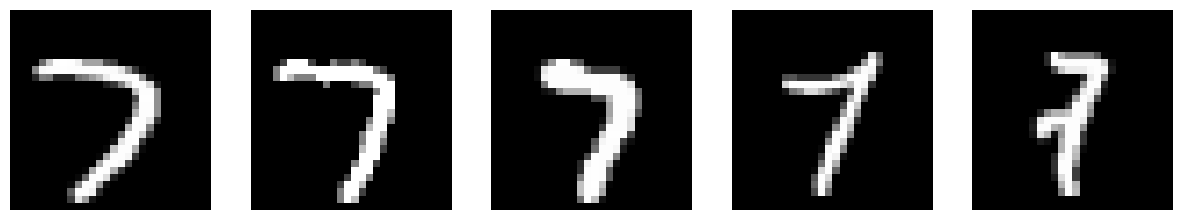

In [ ]:


#ahora vamos a visualizar cinco imagenes de numeros 7
sietes = pixeles[etiquetas == 7].sample(5)

#creamos un grafico con 5 subgraficas
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i in range(5):
    fila_actual = sietes.iloc[i]

    # Convertimos la línea plana a la cuadrícula 2D
    imagen_cuadrada = np.array(fila_actual).reshape(28, 28)

    # Dibujamos en el espacio correspondiente
    axes[i].imshow(imagen_cuadrada, cmap='gray')
    axes[i].axis('off')
plt.show()

Las imagenes que deben ser un 7 si tienen la forma aunque algunas tienen una forma de 1 tambien (como la imagen cuatro). En general la forma es lo unico que tienen similar aunque algunas estan un poco deformadas. La inclinacion y grosor son un poco diferentes pero se alcanza a notar que si son imagenes de un 7.

Las imagenes no son identicas pues si varian en la inclinacion que tiene cada una e igual en el grosor

### Comparación entre clases

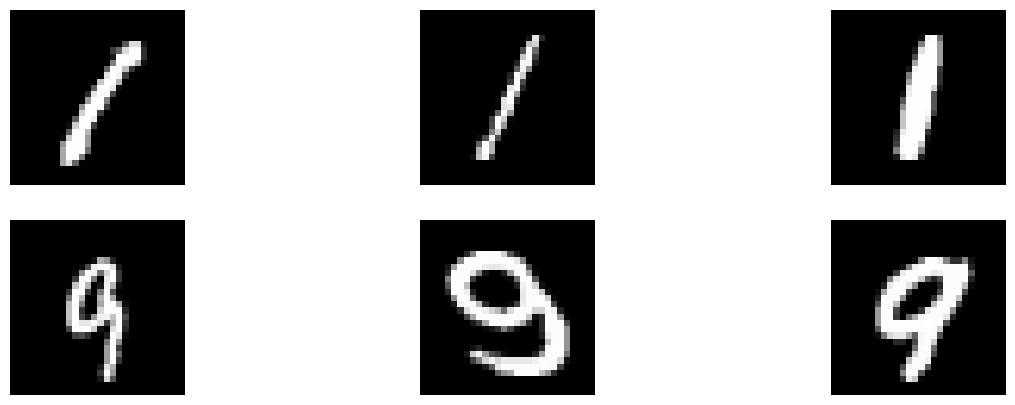

In [ ]:
#vamos a comparar 3 imagenes de unos y 3 imagenes de nueves

unos = pixeles[etiquetas == 1].sample(3)
nueves = pixeles[etiquetas == 9].sample(3)

imagenes = unos, nueves
#mostramos las imagenes
fig, axes = plt.subplots(2, 3, figsize = (15, 5))

for i in range(3):
  fila_actual = unos.iloc[i]

  # Convertimos la línea plana a la cuadrícula 2D
  imagen = np.array(fila_actual).reshape(28, 28)

  # Dibujamos en el espacio correspondiente
  axes[0][i].imshow(imagen, cmap='gray')
  axes[0][i].axis('off')


for i in range(3):
  fila_actual = nueves.iloc[i]

  # Convertimos la línea plana a la cuadrícula 2D
  imagen = np.array(fila_actual).reshape(28, 28)

  # Dibujamos en el espacio correspondiente
  axes[1][i].imshow(imagen, cmap='gray')
  axes[1][i].axis('off')

plt.show()


### Distribucion de clases

/tmp/ipykernel_4374/3118938345.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


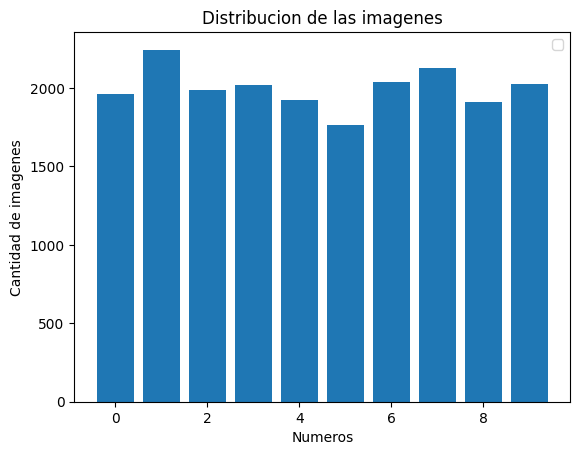

In [ ]:
#generaremos un grafico de barras para ver como se distribuyen la cantidad de numeros en cada clase

numeros = []

for i in range(10):
  numeros.append(len(pixeles[etiquetas == i]))

plt.figure()
plt.bar(range(10), numeros)
plt.title('Distribucion de las imagenes')
plt.xlabel('Numeros')
plt.ylabel('Cantidad de imagenes')
plt.legend()
plt.show()


Podemos ver que la distribucion es muy uniforme y quizá lo fuera si tuvieramos más datos pero si hay unas diferencias entre algunas clases.

El numero 1 es la clase que más muestras tiene mientras que el 5 es el que menos tiene

Conocer la distribucion es importante pues nos ayuda a saber que no hay cargas hacia un lado y que todos los datos tienen el mismo peso


Algo que me llamó la atención fue el numero 1 pues siento que a la vez es facil de reconocer pero a la vez se confunde con el numero 7 o 9. Podemos preguntarnos, ¿es el numero 1 un digito facil de reconocer?

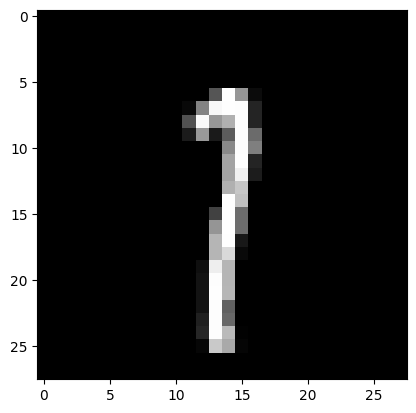

In [ ]:

# la idea es seguir visualizando numeros de la clase 1 de forma aleatoria pero quedarnos con algunos que presenten dificultad de reconocer
uno_aleatorio = pixeles[etiquetas == 1].sample(1)
matriz = np.array(uno_aleatorio).reshape(28, 28)
plt.imshow(matriz, cmap = 'gray')


Despues de correr el codigo unas 25 veces, la mayoria eran imagenes muy reconocibles, solo una o dos tenian una forma un poco rara que quizá se puede confundir con otro numero pero en general la mayoría si son muy distinguibles